In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.mixture import GaussianMixture
from sklearn.metrics import adjusted_rand_score

In [10]:
from pathlib import Path
print(list(Path.cwd().rglob("X_train.txt")))

[PosixPath('/Users/shikh/Downloads/275-final/UCI HAR Dataset/train/X_train.txt')]


In [11]:
ROOT = Path("/Users/shikh/Downloads/275-final/UCI HAR Dataset/") / "train"
ACT = {1: "Walking", 2: "Upstairs", 3: "Downstairs",
       4: "Sitting", 5: "Standing", 6: "Laying"}

In [12]:
# Load training split: 561 engineered features, activity labels, subject IDs
X = pd.read_csv(ROOT / "X_train.txt", sep=r"\s+", header=None).values
y = pd.read_csv(ROOT / "y_train.txt", header=None).values.ravel()
subj = pd.read_csv(ROOT / "subject_train.txt", header=None).values.ravel()

X = StandardScaler().fit_transform(X)
K = 6  # six known activities

In [13]:
# Non-temporal baselines
km = KMeans(n_clusters=K, n_init=10, random_state=0).fit(X)
gmm = GaussianMixture(n_components=K, covariance_type="diag",
                      random_state=0).fit(X)
km_labels = km.labels_
gmm_labels = gmm.predict(X)

ari_km = adjusted_rand_score(y, km_labels)
ari_gmm = adjusted_rand_score(y, gmm_labels)
print(f"ARI  k-means: {ari_km:.3f}   GMM (diag): {ari_gmm:.3f}")

ARI  k-means: 0.422   GMM (diag): 0.247


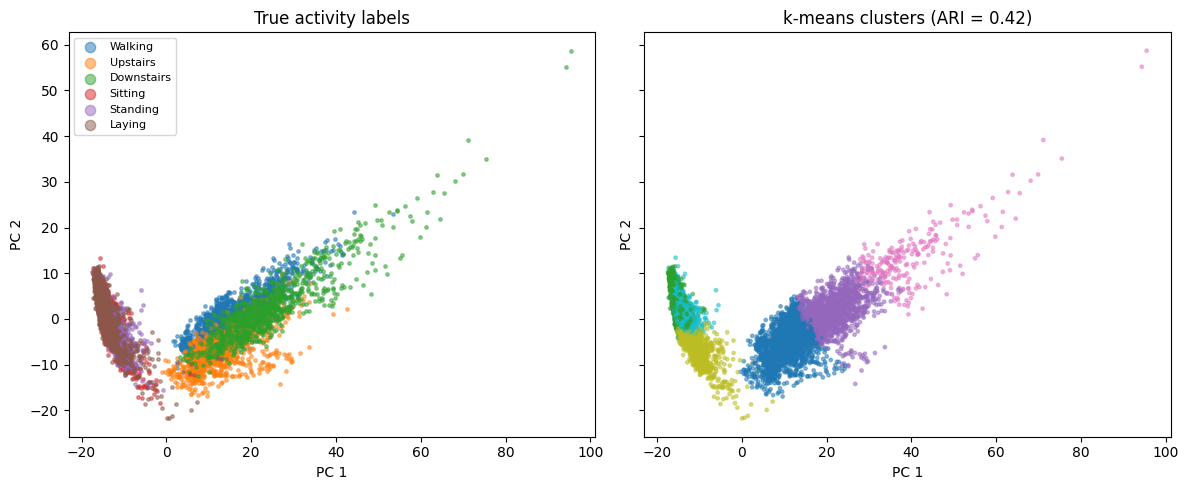

In [14]:
# Figure 1: 2D PCA projection, colored by truth and by k-means clusters
Z = PCA(n_components=2, random_state=0).fit_transform(X)
fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharex=True, sharey=True)

for a in sorted(ACT):
    m = y == a
    axes[0].scatter(Z[m, 0], Z[m, 1], s=6, alpha=0.5, label=ACT[a])
axes[0].set_title("True activity labels")
axes[0].legend(markerscale=3, fontsize=8)

axes[1].scatter(Z[:, 0], Z[:, 1], c=km_labels, cmap="tab10", s=6, alpha=0.5)
axes[1].set_title(f"k-means clusters (ARI = {ari_km:.2f})")

for ax in axes:
    ax.set_xlabel("PC 1")
    ax.set_ylabel("PC 2")

fig.tight_layout()
fig.savefig("prelim_pca.pdf")

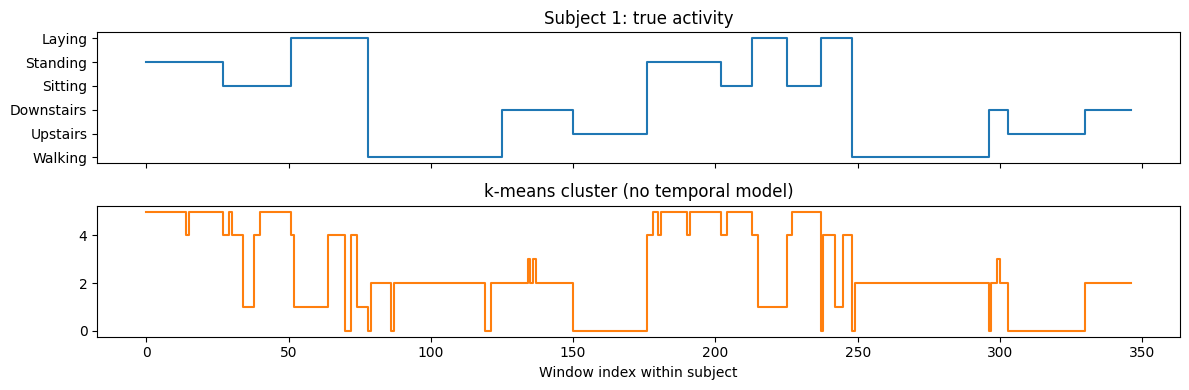

In [15]:
# Figure 2: one subject's sequence, true labels vs k-means labels over time
s = np.unique(subj)[0]
idx = np.where(subj == s)[0]
fig, ax = plt.subplots(2, 1, figsize=(12, 4), sharex=True)
ax[0].step(np.arange(len(idx)), y[idx], where="post")
ax[0].set_yticks(list(ACT))
ax[0].set_yticklabels(list(ACT.values()))
ax[0].set_title(f"Subject {s}: true activity")

ax[1].step(np.arange(len(idx)), km_labels[idx], where="post", color="C1")
ax[1].set_title("k-means cluster (no temporal model)")
ax[1].set_xlabel("Window index within subject")
fig.tight_layout()
fig.savefig("prelim_sequence.pdf")

plt.show()